# Klasifikasi MNIST Menggunakan ANN (TensorFlow)

Notebook ini mencakup preprocessing, pembangunan model ANN, pelatihan, dan evaluasi pada dataset MNIST.

## 1. Import Library
TensorFlow digunakan untuk membangun dan melatih model. Scikit-learn digunakan untuk metrik evaluasi.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

tf.random.set_seed(42)
np.random.seed(42)

## 2. Load Dataset MNIST
MNIST berisi citra angka tulisan tangan berukuran 28 × 28 piksel dengan label 0–9.

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print('Data train:', x_train.shape)
print('Data test :', x_test.shape)
print('Jumlah kelas:', len(np.unique(y_train)))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Data train: (60000, 28, 28)
Data test : (10000, 28, 28)
Jumlah kelas: 10


## 3. Preprocessing
Nilai piksel dinormalisasi ke rentang 0–1, kemudian setiap citra 28 × 28 diubah menjadi vektor 784 fitur agar sesuai dengan input ANN berbasis Dense.

In [3]:
# Normalisasi piksel
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Flatten: 28 x 28 menjadi 784 fitur
x_train = x_train.reshape(-1, 28 * 28)
x_test = x_test.reshape(-1, 28 * 28)

print('Bentuk data train setelah preprocessing:', x_train.shape)
print('Bentuk data test setelah preprocessing :', x_test.shape)

Bentuk data train setelah preprocessing: (60000, 784)
Bentuk data test setelah preprocessing : (10000, 784)


## 4. Membangun Model ANN
Model menggunakan dua hidden layer dengan aktivasi ReLU dan output 10 neuron dengan Softmax untuk klasifikasi angka 0–9.

In [4]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Training Model
Data training dibagi secara internal oleh `validation_split` untuk memantau performa selama pelatihan. Data test tidak digunakan dalam proses training.

In [5]:
history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9036 - loss: 0.3466 - val_accuracy: 0.9627 - val_loss: 0.1369
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9572 - loss: 0.1469 - val_accuracy: 0.9700 - val_loss: 0.1042
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9704 - loss: 0.1018 - val_accuracy: 0.9733 - val_loss: 0.0941
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9778 - loss: 0.0757 - val_accuracy: 0.9738 - val_loss: 0.0923
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9838 - loss: 0.0584 - val_accuracy: 0.9735 - val_loss: 0.0946
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9874 - loss: 0.0460 - val_accuracy: 0.9720 - val_loss: 0.0974
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9909 - loss: 0.0356 - val_accuracy: 0.9712 - val_loss: 0.0993
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9927 - loss: 0.0286 - val_accuracy: 0.

## 6. Evaluasi Model
Evaluasi dilakukan pada data test menggunakan loss dan accuracy.

In [6]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f'Test Loss     : {test_loss:.4f}')
print(f'Test Accuracy : {test_accuracy:.4%}')

Test Loss     : 0.1020
Test Accuracy : 97.3400%


## 7. Grafik Training
Grafik digunakan untuk melihat perubahan accuracy dan loss pada data training serta validation selama proses pelatihan.

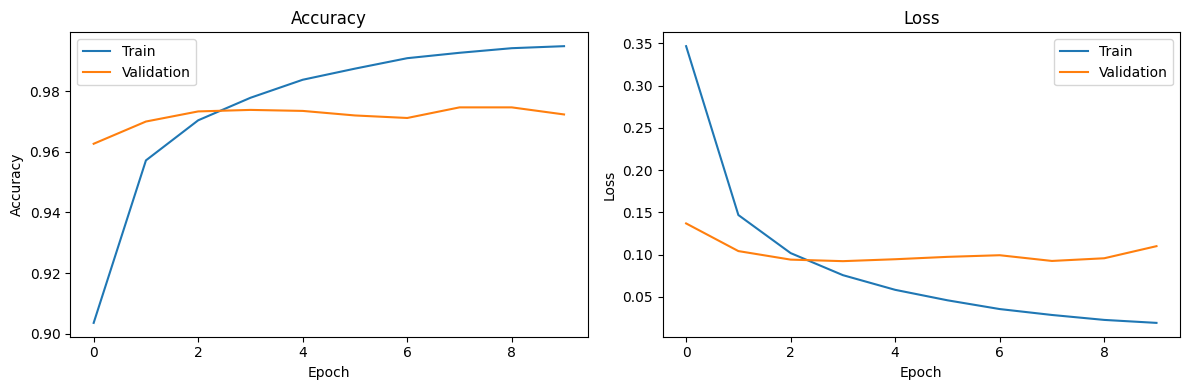

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(history.history['accuracy'], label='Train')
ax[0].plot(history.history['val_accuracy'], label='Validation')
ax[0].set_title('Accuracy')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Accuracy')
ax[0].legend()

ax[1].plot(history.history['loss'], label='Train')
ax[1].plot(history.history['val_loss'], label='Validation')
ax[1].set_title('Loss')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Loss')
ax[1].legend()

plt.tight_layout()
plt.show()

## 8. Classification Report dan Confusion Matrix
Classification report menampilkan precision, recall, dan F1-score untuk setiap kelas. Confusion matrix memperlihatkan jumlah prediksi benar dan salah pada tiap kelas.

              precision    recall  f1-score   support

           0     0.9877    0.9816    0.9846       980
           1     0.9868    0.9877    0.9872      1135
           2     0.9794    0.9661    0.9727      1032
           3     0.9519    0.9802    0.9659      1010
           4     0.9680    0.9868    0.9773       982
           5     0.9828    0.9630    0.9728       892
           6     0.9822    0.9781    0.9801       958
           7     0.9899    0.9572    0.9733      1028
           8     0.9210    0.9815    0.9503       974
           9     0.9876    0.9504    0.9687      1009

    accuracy                         0.9734     10000
   macro avg     0.9737    0.9733    0.9733     10000
weighted avg     0.9740    0.9734    0.9735     10000



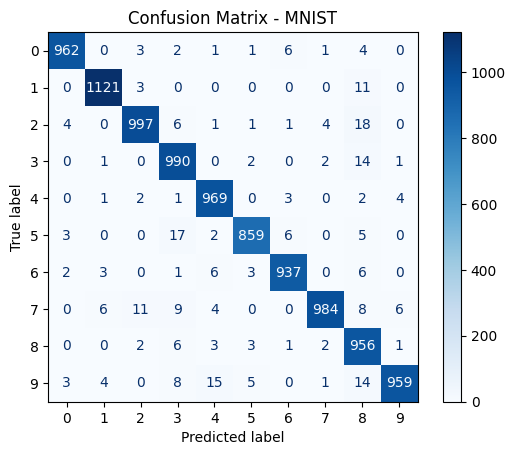

In [8]:
y_pred = np.argmax(model.predict(x_test, verbose=0), axis=1)

print(classification_report(y_test, y_pred, digits=4))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=range(10))
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix - MNIST')
plt.show()

## 9. Kesimpulan

Berdasarkan hasil pelatihan dan evaluasi model, dapat ditarik beberapa kesimpulan:

1. **Performa Keseluruhan**: Model Artificial Neural Network (ANN) yang dibangun berhasil mengklasifikasikan citra angka tulisan tangan dataset MNIST dengan sangat baik, mencapai **Test Accuracy sebesar 97.34%** dan Test Loss sebesar 0.1020.
2. **Analisis Overfitting**: Berdasarkan grafik *training* dan *validation*, akurasi pada data latih mencapai hampir 99.5%, namun akurasi pada data validasi stagnan di kisaran 97.2%. Jarak (*gap*) yang melebar pada grafik loss juga menunjukkan adanya indikasi *overfitting ringan*. Penambahan metode regularisasi seperti *Dropout* dapat membantu meningkatkan kemampuan generalisasi model.
3. **Performa per Kelas**: Melalui *Classification Report* dan *Confusion Matrix*, terlihat bahwa model sangat stabil mengenali semua angka dengan F1-score rata-rata di atas 97%. Presisi terendah ada pada kelas angka 8 (92.10%), yang berarti model kadang kala keliru menebak angka lain sebagai angka 8. Secara keseluruhan, model sudah sangat andal untuk tugas klasifikasi ini.